# CS3630 Project 4: State Estimation and Value Iteration
Fall 2026

## Brief
Implement **eight functions in `project4.py`**. First build a particle filter to estimate the robot's position, then use value iteration to plan a route, and finally run experiments with both in the Webots warehouse. The map, utilities, proximity sensor model, and policy extraction are provided.

## Setup
```bash
conda create -n cs3630_p4 python=3.12
conda activate cs3630_p4
python -m pip install -r requirements.txt
```
Run these in this project folder. Open this notebook in VS Code with the `cs3630_p4` kernel, or run `jupyter lab` here and open `project4.ipynb`. Edit and save `project4.py`, then rerun the relevant check or example; autoreload picks up your saved changes. Use NumPy and the standard library, keep the supplied signatures, and do not modify inputs. Functions with an `rng` argument must use that generator for all randomness.

The general Webots setup and controls are below, before Part 1.

## Submission
Submit `project4.py` for the **50-point code assignment**. Answer **Q1-Q7 in `project4_reflection.pptx`**, replace the cover name and GTID, and export it as PDF for the **50-point report**; Q8-Q9 offer **10 optional extra-credit points**. Assign each question to its answer pages on Gradescope. The notebook is not submitted.

For each question, include the requested report evidence and your written reflection in the PowerPoint report, adding slides as needed before exporting to PDF.

Use brief explanations supported by the requested plots and results; derivations are not required. Follow the syllabus's academic-integrity expectations.


In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "project4.py").exists(), "Open the notebook from its project folder."
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "webots" / "support"))
# Local modules must be imported after adding their directories to sys.path.
import project4 as p4  # noqa: E402
from notebook_tools import check, check_all, show  # noqa: E402

## Conventions
- Positions and particles are **(x, y)** in meters; particle arrays have shape `(N, 2)`.
- Maps have shape `(50, 100)` and use **[row, column] = [y, x]**. Use `point_to_cell`, `points_to_cells`, `cell_to_point`, and `next_cell` to convert or move between cells.
- Actions are `0 WEST`, `1 EAST`, `2 SOUTH`, `3 NORTH` and move one meter.
- A zone reading is a zone id: an index into `ZONE_NAMES` (25 zones: the RECEIVING and SHIPPING bays, AISLE 1-3, and the two cross aisles). `ZONE_MAP[i, j]` is the zone of cell `(i, j)`, `-1` for shelf cells.

Enter your name and GT username in `student_info()`. This is setup, not another algorithm TODO.


## How to run the Webots experiments
The Webots experiments are preset in the warehouse. Select a test and its setting at the briefing, then press **SPACE** to run it. Each test ends with a results table.

**One-time setup:** With `cs3630_p4` activated, run `python -c "import sys; print(sys.executable)"` in a terminal. In **Webots > Preferences** on macOS or **Tools > Preferences** on Windows/Linux, paste that path into **General > Python command**, then restart Webots.

Choose **File > Open World** and open `webots/worlds/warehouse_challenge.wbt`. Press **Run** (the play button) if the simulation is paused, and **click inside the 3D view** so that it receives your keys.

1. **Pick the experiment.** At the MISSION BRIEFING, press **E** until the experiment you want is green in the `[E]` line: MISSION, START TEST, SENSOR TEST, PENALTY TEST, OBSTACLE TEST.
2. **Pick its setting, if available.** Press the number key shown on the card (for example **1-5** for the sensor test). The chosen setting turns green.
3. **Start.** Press **SPACE**. The top banner names the test, and the line under it says what it changes.
4. **Read the results.** At the end, a table lists every test of this experiment that you ran since Webots started. Each reflection specifies the evidence to capture and its timing. Use **File > Take Screenshot** in Webots or your system's screenshot tool.
5. **Next test.** Press **R** to go back to the briefing, and pick the next setting with its number key.

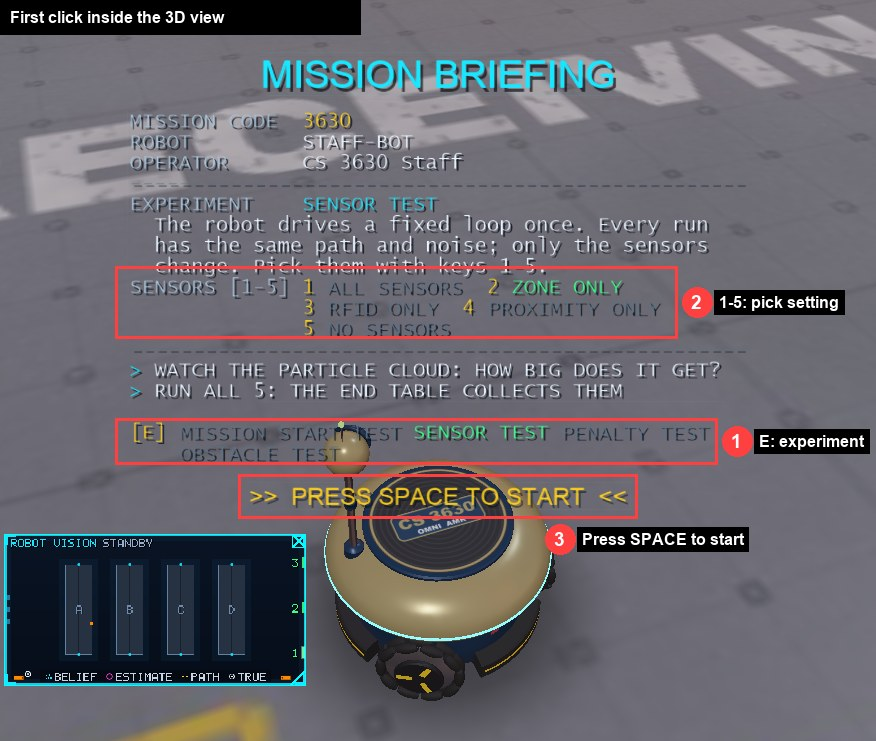

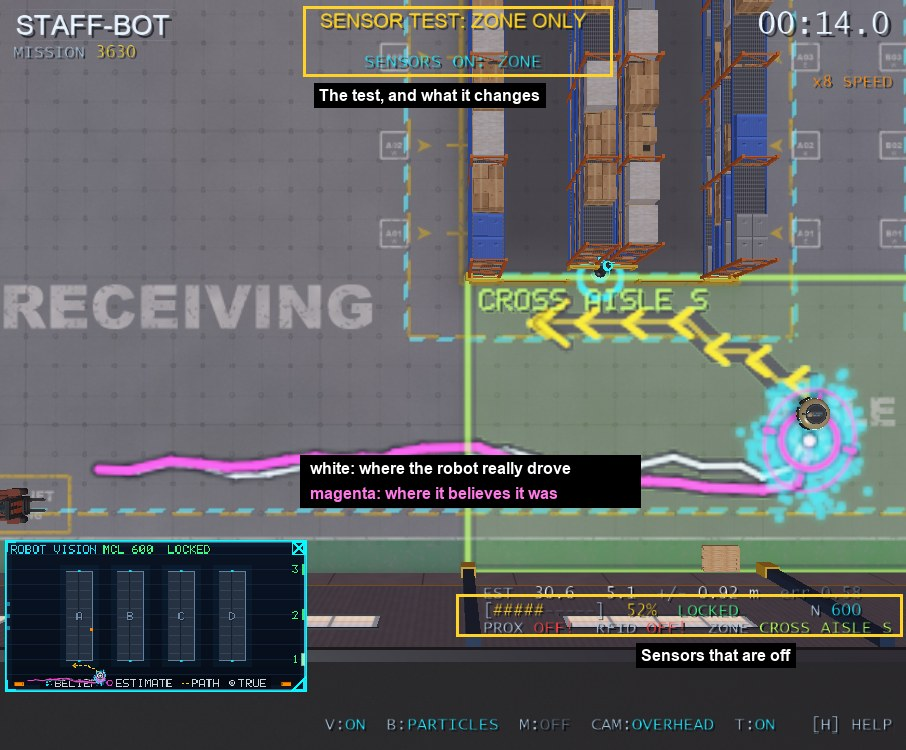

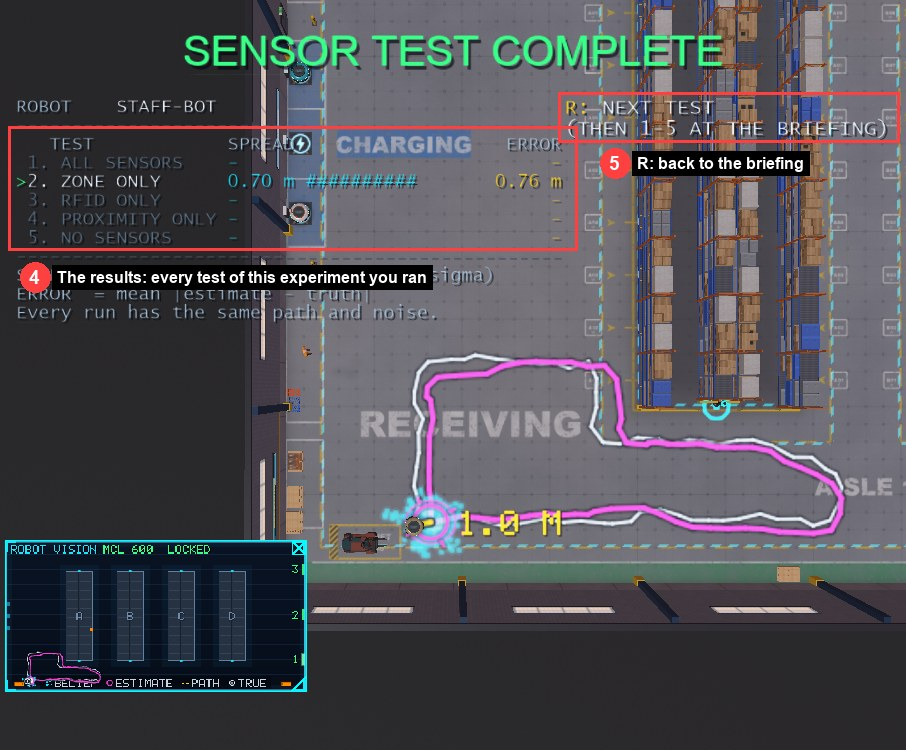

What each experiment isolates:

| Experiment | Tests your | How the robot moves | Particle filter | Start |
|---|---|---|---|---|
| START TEST | filter (TODOs 1-6) | a fixed loop, steered by its **true** position | yes, 2000 particles, all sensors | known (key 1) or unknown (key 2) |
| SENSOR TEST | filter (TODOs 1-6) | the same fixed loop, steered by its **true** position | yes, with the sensors you pick (keys 1-5) | known |
| PENALTY TEST | planner (TODOs 7-8) | your value function | no: the robot is told its **exact** position | a fixed delivery |
| OBSTACLE TEST | filter and planner | your value function, voted by your particles | yes | unknown (a normal mission) |

In the START and SENSOR TESTS the robot drives like a train on a track: its path never depends on your estimate, so only the belief (the magenta line and the particle cloud) shows what your code does.

### What you see on the floor
Press **V** to show or hide the floor visualizations.

| Visualization | Meaning |
|---|---|
| Cyan dots | Particles; larger dots have higher weights |
| Magenta ring + ellipse | Estimated position (weighted mean) and 2σ uncertainty |
| Orange ring around a beacon | RFID range measurement |
| Lime outline | Zone reported by the zone reader |
| Yellow chevrons + rings | Planned route and goal |
| White + magenta lines | True (white) and estimated (magenta) trajectories; a yellow line connects their final positions |
| Orange line (Penalty Test) | Route from the other penalty setting |
| Red cells (Obstacle Test) | Cells where the value function decreased |

The robot shows its true position. The minimap at the bottom left gives an overview of the warehouse, with a white dot marking the true position.

Other useful controls:
- **B:** Toggle particles.
- **M:** Cycle map layers: value function, sensor likelihood, zones, or off; value changes are also available after an obstacle drops.
- **2:** Select the overhead camera during a run.
- **T:** Toggle turbo speed.
- **H:** Show every key.

Rerunning the same test setting gives the same numbers. You can pause the simulation to capture a screenshot.


## Part 1: State estimation
The robot maintains a **belief** over possible positions. Particles approximate that belief: motion changes their positions, measurements change their weights, and resampling carries likely hypotheses forward. We summarize the result using a weighted mean and covariance.

A known starting position gives a concentrated prior; an unknown start needs a broad prior. Sensors will not always identify a unique position from one reading.

The robot has **three sensors**, and the Webots robot uses all of them:

| Sensor | What it reads | Likelihood |
|---|---|---|
| Proximity | ON within 2 m of a shelf, wall, or obstacle, else OFF | `proximity_likelihood` (provided) |
| RFID reader | the id and range of the nearest beacon within 8 m, or `(None, inf)` | `rfid_likelihood` (TODO 2) |
| Zone reader | which of the 25 zones the robot is in (not where in it) | `zone_likelihood` (TODO 3) |

`mcl_update` (TODO 5) multiplies the three. (At a rack or a dock, a camera also reads a marker for a precise position fix; the Webots engine does that part for you.)

**Where they are** (in Webots, press **M** until the map layer is ZONES):
- **RFID beacons:** 8, one at each end of every shelf block, west to east: ids 0-3 on the south ends (y = 9.5 m) and 4-7 on the north ends (y = 39.5 m). The reader hears the nearest beacon within 8 m, so it helps only near the ends of the shelves.
- **Zones:** RECEIVING (west of shelf A) and SHIPPING (east of shelf D) are cut into 10 m x 10 m bays, numbered 1-5 from the south with W and E halves (e.g. SHIPPING 3E); AISLE 1-3 lie between the shelf blocks; CROSS AISLE S and N run along their south and north ends. `ZONE_MAP` and `ZONE_NAMES` in `project4.py` hold this layout.
- **Proximity:** ON in a 2 m band around every shelf block and along the walls (`PROXIMITY_MAP_ON`).

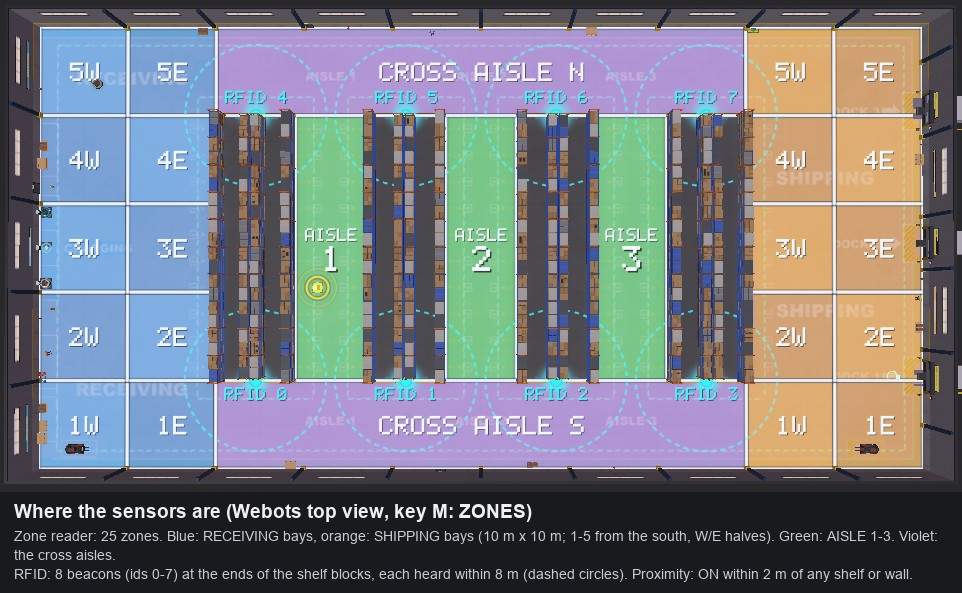


### TODO 1: `sample_motion_model`
Because commanded motion is imperfect, we need to represent the range of positions the robot could reach.

Sample the commanded movement plus independent Gaussian noise for every coordinate of every state. Accept one position `(2,)` or a batch `(N, 2)` and preserve its shape. Use the supplied `rng` and return a fresh array.

The motion model is `next position = current position + command + noise`. One shared noise vector would move the entire cloud together without representing different outcomes.


PASS  sample_motion_model: all 2 public tests pass.


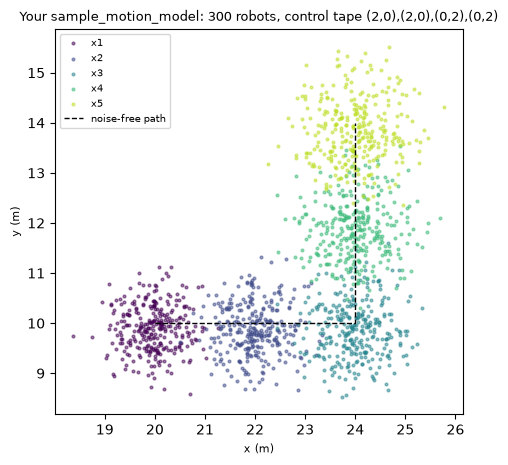

In [2]:
check("sample_motion_model")
show.motion(p4)

### TODO 2: `rfid_likelihood`
An RFID range reading can fit several possible positions, so we need a likelihood to compare those hypotheses.

A beacon ID and range favor positions at approximately that distance from the identified beacon. Return the unnormalized Gaussian range likelihood inside `max_range`, and zero outside it. A `(None, inf)` reading favors positions outside the range of **every** beacon.

Return one value per point, use the supplied parameters, and distinguish beacon ID `0` from `None`. The starter docstring gives the exact formula.


PASS  rfid_likelihood: all 3 public tests pass.


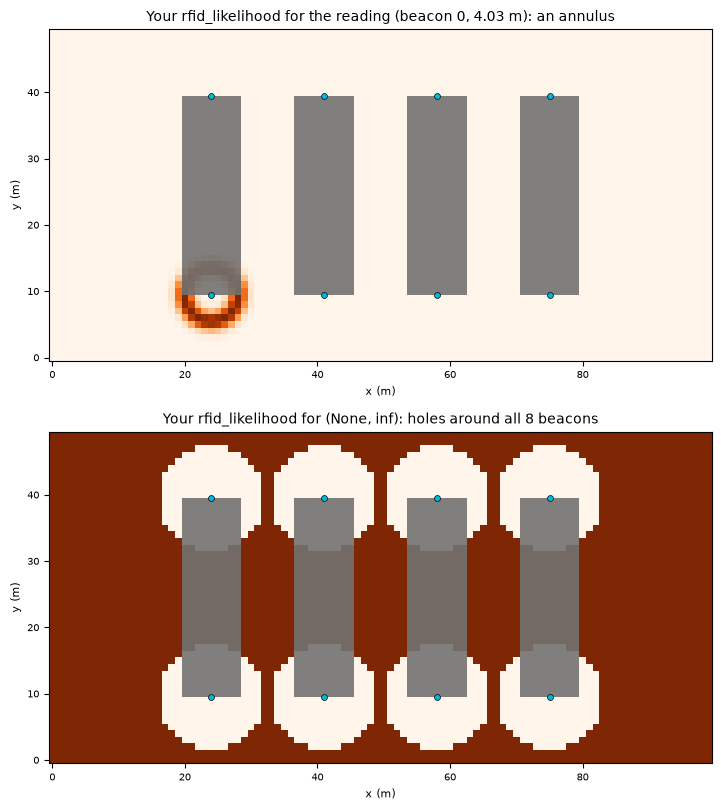

In [3]:
check("rfid_likelihood")
show.rfid(p4)

### TODO 3: `zone_likelihood`
The zone reader narrows the robot's possible area without giving an exact position, so we need to score particles against that zone.

The robot's zone reader hears the IR zone beacon of the area it is in, so it reports a **zone id**, not a position. Look up each point's zone in `zone_map`: the likelihood is `p_correct` if it matches the reading, `(1 - p_correct) / (num_zones - 1)` for any other zone (the reader sometimes names the wrong zone), and `0` for points in a shelf or off the map.

Use the supplied `zone_map`, `p_correct`, and `num_zones` rather than fixed constants. The proximity lookup is provided; compare how the three sensors constrain the same possible positions.


PASS  zone_likelihood: all 2 public tests pass.


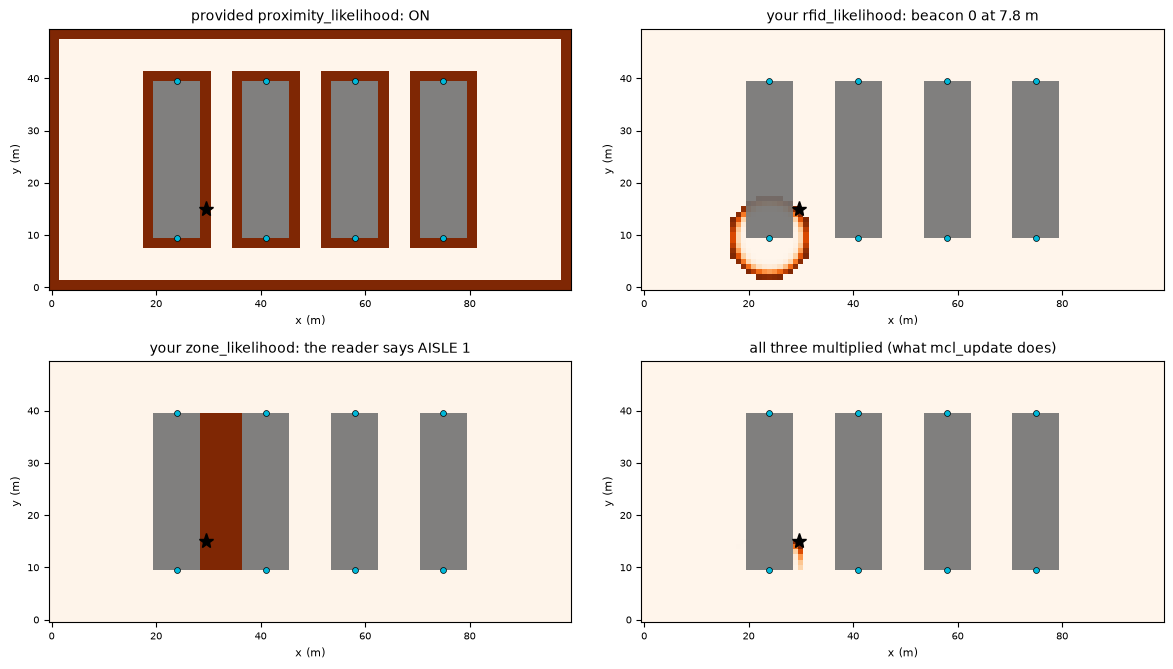

In [4]:
check("zone_likelihood")
show.sensors(p4)

### TODO 4: `mcl_predict`
After the robot moves, we must carry likely position hypotheses forward and account for the new motion uncertainty.

Normalize a copy of the current weights, draw particle indices **with replacement** according to those weights, and pass the selected particles through TODO 1. Use `num_samples` when supplied; otherwise preserve the particle count.

This implementation resamples the previous posterior as part of the next prediction. Each copy of a selected particle must receive its own motion-noise sample.


In [5]:
check("mcl_predict")

PASS  mcl_predict: all 3 public tests pass.


### TODO 5: `mcl_update`
To correct the motion prediction, we need to give more weight to positions that agree with the sensors.

For each particle, multiply the proximity, RFID, and zone likelihoods. Omit the zone factor when its measurement is `None`. This product assumes the sensor readings are conditionally independent given position.

Return **raw weights**, not normalized weights. A measurement update changes the plausibility of existing positions; it does not move the particles.


In [6]:
check("mcl_update")

PASS  mcl_update: all 2 public tests pass.


### TODO 6: `estimate_position`
To guide the robot, we need a position estimate and a measure of how uncertain it is.

Normalize a copy of the weights and compute the weighted mean and weighted **population covariance**. Return shapes `(2,)` and `(2, 2)`; there is no `N-1` correction.

The mean summarizes the position, while covariance describes spread. A mean alone can hide multiple separated hypotheses, so inspect the particle plot too.


PASS  estimate_position: all 2 public tests pass.


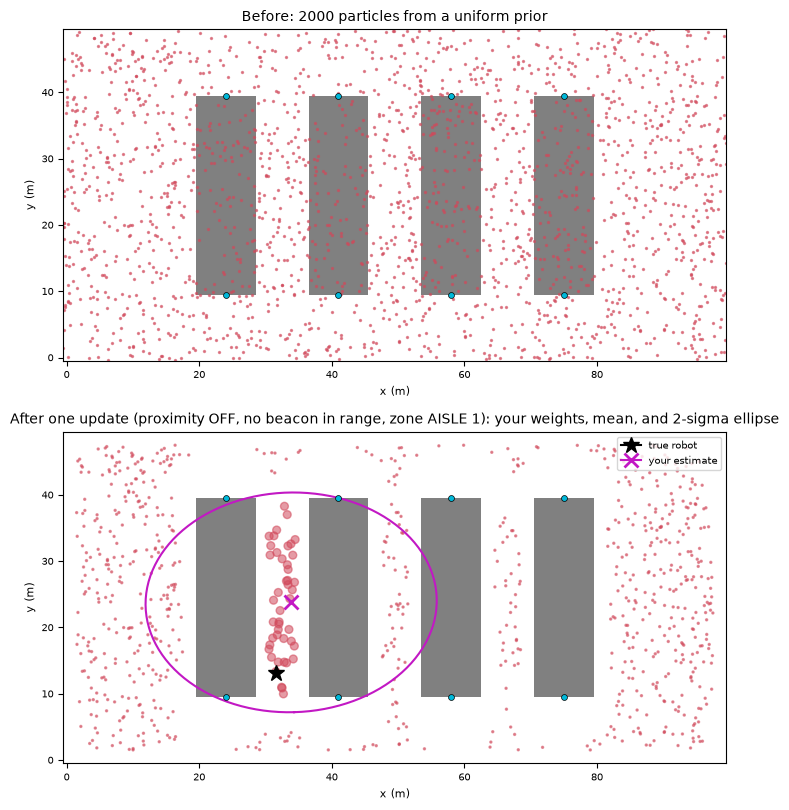

In [7]:
check("estimate_position")
show.mcl(p4)

### Reflection Q1 [4 points]

**Report evidence:** Include the motion-model plot.

**Written reflection:** Explain why the particle cloud spreads after movement and why each particle needs independent noise. Describe how resampling changes which possible positions are carried into the next prediction.


### Reflection Q2 [3 points]

**Written reflection:** Explain your `rfid_likelihood` implementation in your own words, including how it handles a detected beacon and a no-detection reading.


### Webots experiment: starting belief (Q3)
Run **START TEST** twice with **2000 particles**, using key **1** for a known start and key **2** for an unknown start. Both runs use all sensors, the same physical start, and the same path and noise. The robot follows a fixed loop using its true position, so its path does not depend on your estimate; only the filter's starting belief changes.

| Run | Key | Starting belief |
|---|---|---|
| A | 1 | Known start: particles begin around the robot |
| B | 2 | Unknown start: particles begin across the floor |

Watch the particle cloud, especially the first seconds of run B. White shows where the robot drove and magenta shows where it believed it was. The results table reports **ERROR**, **FIRST 6 S** (mean error during the first 6 seconds), and **SPREAD** (the size of the particle cloud).


### Reflection Q3 [8 points]

**Report evidence:** Four labeled screenshots, two for each run A-B: **Beginning** (initial particle cloud just after deployment) and **End** (final particle cloud, results table, and floor). Record ERROR, FIRST 6 S, and SPREAD for each run. A failed or unfinished run is valid evidence.

**Written reflection:** Explain how the starting belief affects initial uncertainty and localization over time, including how a broad prior concentrates as measurements arrive. Use the beginning and end particle clouds and reported results to compare the runs.


### Webots experiment: sensor information (Q4)
Run **SENSOR TEST** with the settings below. Every run uses a known start and the same path and noise. The robot follows a fixed loop using its true position, so only the localization measurements change; keep your implementations unchanged.

| Run | Key | Localization measurements |
|---|---|---|
| A | 1 | All: proximity, RFID, and zone |
| B | 5 | None: motion prediction only |
| C | 2, 3, or 4 | One of your choice: zone only (2), RFID only (3), or proximity only (4) |

White shows where the robot drove, magenta shows where it believed it was, and yellow joins the robot to its final estimate. The results table reports **SPREAD** and **ERROR**.


### Reflection Q4 [10 points]

**Report evidence:** Three labeled end-of-run screenshots, one per run A-C, with the results table and floor visible. Name your chosen sensor and record SPREAD and ERROR for each run.

**Written reflection:** Compare the beliefs and reported results. Explain how measurement weighting affects MCL, why prediction alone can drift, and what ambiguity remains with your chosen sensor.


## Part 2: Planning with value iteration
The goal is a grid cell. Value iteration assigns each cell the best discounted return available from its four actions. A reward encourages reaching the goal; proximity penalties discourage traveling near shelves and boundaries.

You implement the action-value calculation and the repeated Bellman updates. The supplied `greedy_action` extracts a policy from your values; it is not a separate planner.


### TODO 7: `q_value`
Before choosing a route, we need a way to compare a move's immediate cost with the progress it enables toward the goal.

Return zero at goal and obstacle cells. Else use `next_cell` to compute the destination, then return its reward plus `gamma * V[next]`.

The reward is **+100 when entering the goal**, minus **50 for proximity at the current cell**, minus **50 for proximity at the next cell**. Use the named constants and supplied maps; an off-map move stays in place. Do not introduce a different obstacle-transition rule—the function contract and tests use this specific model.


In [8]:
check("q_value")

PASS  q_value: all 3 public tests pass.


### TODO 8: `value_iteration`
To plan beyond one move, we need to propagate information about reaching the goal throughout the map.

Start with zeros. In each **synchronous sweep**, set each nonterminal cell to the largest of its four action values, calculated from the **previous** value map. Keep goal and obstacle cells at zero.

Stop when the largest absolute change is at most `tol`, or when `max_iterations` is reached. Support matching maps of arbitrary shape. A clear loop implementation is acceptable; vectorized Bellman updates are also allowed. The provided route helper will use your result without any additional planning TODO.


In [9]:
check("value_iteration")

PASS  value_iteration: all 3 public tests pass.


### Reflection Q5 [10 points]

**Report evidence:** Use the notebook helper to compare value maps after 1, 10, and 40 sweeps and at convergence. Include these maps and the final Bellman residual, the largest change from one more optimal backup.

**Written reflection:** Explain how information about the goal spreads through the map and why each sweep uses the previous value map. Describe what stopping too early could change.


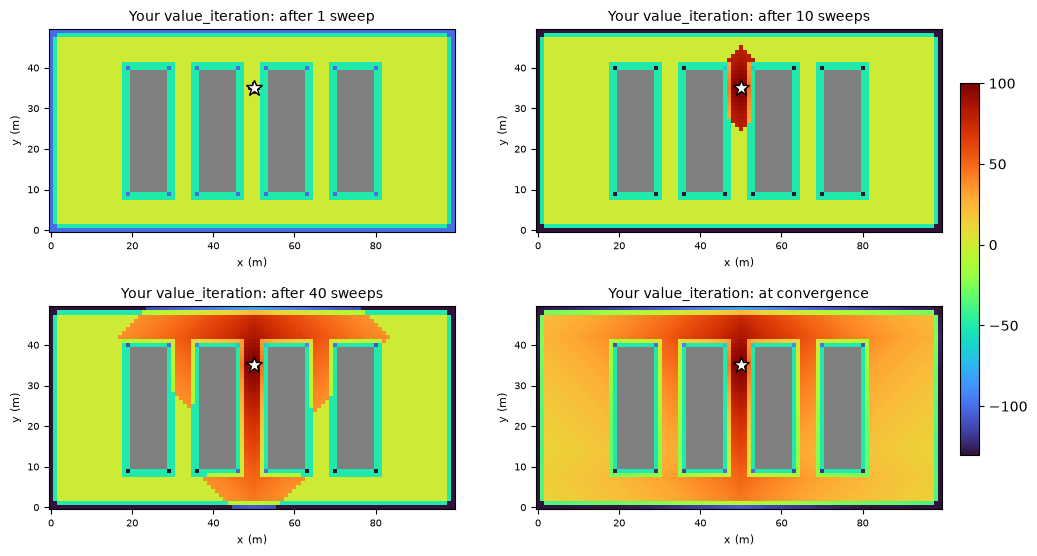

Bellman residual of the converged map (largest change from one more optimal backup): 0.00e+00


In [10]:
value_map = show.planning(p4, experiment="convergence")

### Webots experiment: reward design (Q6)
Run **PENALTY TEST** twice: key **1** uses a proximity penalty of **50** and key **2** uses **0**. This tests planning only: the robot is given its exact position and does not use the particle filter. Both runs deliver the same order from the same start with the same noise; only the planner's reward changes.

The results table reports **ROUTE** (planned route length in meters, including start-to-rack and rack-to-dock), **PROX ON** (route cells with proximity ON), **STOPS** (safety stops), **TIME**, and **RESULT** (COMPLETE or FAILED). Wheels can still slip, and a stuck run ends after about two minutes. White shows the current route; after the second run, orange shows the other run's route.


### Reflection Q6 [10 points]

**Report evidence:** Two labeled end-of-run screenshots, one per penalty setting, showing the routes and results table. Report ROUTE, PROX ON, STOPS, TIME, and RESULT for each run.

**Written reflection:** Explain how the reward change affects the selected route and its distance from shelves and walls. If the routes are similar, explain why that can happen.


## Part 3: Putting it together
Your particle filter estimates the robot's position and your value-iteration policy guides its movements. In this section, run **one Webots experiment** to see how a new obstacle changes the value map and the route, and how the robot follows the new route when it only knows its belief.

There are no new TODOs. First confirm that all eight function checks pass.


In [11]:
check_all()

TODO  function               public tests  status
   0  student_info               1 / 1      PASS
   1  sample_motion_model        2 / 2      PASS
   2  rfid_likelihood            3 / 3      PASS
   3  zone_likelihood            2 / 2      PASS
   4  mcl_predict                3 / 3      PASS
   5  mcl_update                 2 / 2      PASS
   6  estimate_position          2 / 2      PASS
   7  q_value                    3 / 3      PASS
   8  value_iteration            3 / 3      PASS

9 of 9 rows pass all their public tests.
Every public test passes. Next: the Webots experiments.


### Webots experiment: the obstacle test (Q7)
Run **OBSTACLE TEST** using the general controls above. This uses the whole system: your particle filter estimates position and your value function plans the route. A few seconds after localization locks on, an obstacle drops on the route. Red highlights show where the value function decreased, and the robot replans while navigating with its belief. The obstacle is also added to the proximity map; keep the goal and discount factor fixed.

Observe the particle cloud and estimate as the robot approaches and passes the obstacle.


### Reflection Q7 [5 points]

**Report evidence:** Two screenshots: just after the obstacle drops and while the robot drives around it, showing the red value changes, particle cloud, estimate, and new route across the two views.

**Written reflection:** For planning, explain which traversable cells lost value and why others could stay unchanged. How does the planner choose a route around the new obstacle? For localization, explain how particle voting and uncertainty could affect route choice or hesitation near the obstacle, using your observations. What new information does the obstacle add through the proximity sensor?


## Optional extra credit
These extend the same particle filter and value-iteration algorithm. No additional implementation is required.


### Reflection Q8 [5 extra-credit points]

**Report evidence:** Run the particle-filter comparison with assumed motion noise of 0.2 and 1.0 meters on the same recorded data. Include the error and belief-spread plots.

**Written reflection:** Explain what the results suggest about confidence and motion-model mismatch.


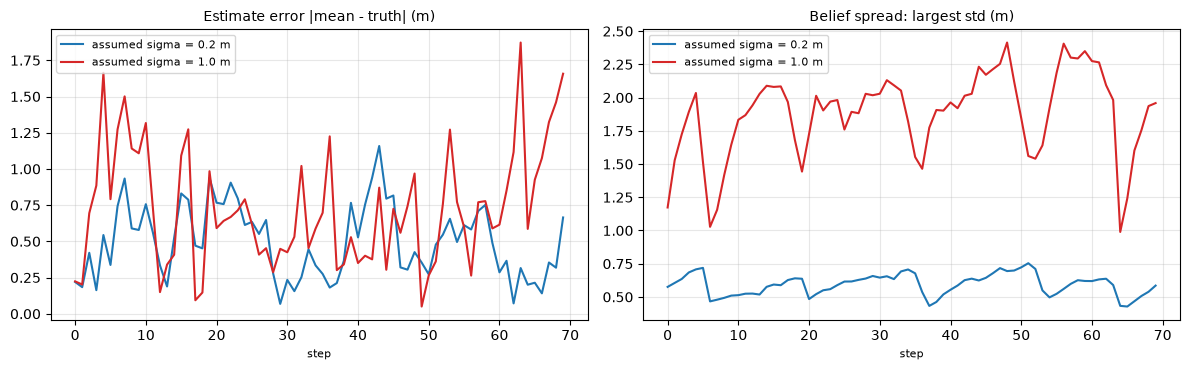

assumed sigma 0.2 m: mean error 0.50 m, mean spread 0.59 m
assumed sigma 1.0 m: mean error 0.73 m, mean spread 1.88 m


In [12]:
noise_results = show.localization(p4, experiment="noise")

### Reflection Q9 [5 extra-credit points]

**Report evidence:** Compare value iteration with discount factors 0.90 and 0.975 using the same map and rewards. Include the value maps and route results.

**Written reflection:** Explain why the values change and whether the selected route changes.


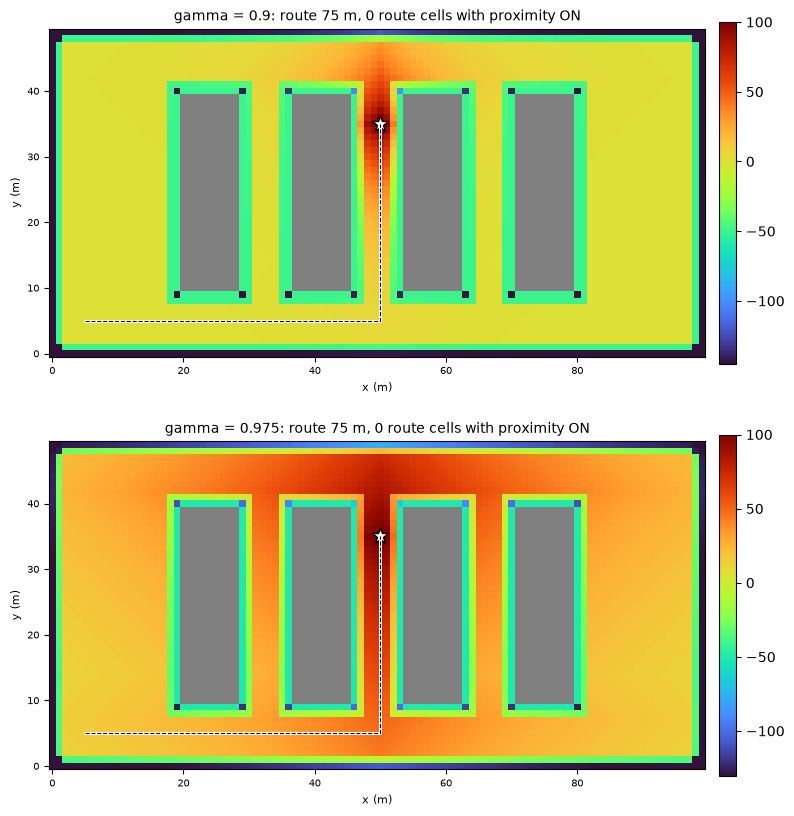

gamma 0.9: V at the start    0.041, route 75 m, 0 cells with proximity ON, goal reached
gamma 0.975: V at the start   15.358, route 75 m, 0 cells with proximity ON, goal reached
The two routes are the same.


In [13]:
discount_results = show.planning(p4, experiment="discount")